# Home Credit : scoring du risque de défaut de crédit
## Notebook 03 : historique de crédit externe (bureau de crédit) en SQL

Le bureau de crédit recense les crédits que les clients ont contractés **auprès d'autres organismes**. C'est l'information qu'un banquier consulte en premier : un client qui a déjà eu des retards ailleurs, ou qui est déjà très endetté, est plus risqué.

Deux tables :

| Table | Une ligne par… | Lignes | Clé |
|---|---|---|---|
| `bureau` | crédit déclaré au bureau | 1,7 million | `SK_ID_BUREAU`, rattaché au client par `SK_ID_CURR` |
| `bureau_balance` | crédit et par mois | 27,3 millions | `SK_ID_BUREAU` |

```
bureau_balance ──(agrégée par crédit : SK_ID_BUREAU)──► bureau ──(agrégée par client : SK_ID_CURR)──► application
   27,3 M lignes                                         1,7 M lignes                                  1 ligne par client
```

Un client ayant plusieurs crédits, et chaque crédit plusieurs mois d'historique, on ne peut pas joindre ces tables directement à la table principale : il faut d'abord **agréger** en résumant l'historique de chaque client par quelques indicateurs (nombre de crédits, endettement, retards…). C'est le travail typique du langage SQL.

On utilise **DuckDB**, une base de données analytique qui s'exécute dans Python sans serveur, lit directement les fichiers CSV et traite des dizaines de millions de lignes en quelques secondes.

In [3]:
import sys
import time
from pathlib import Path

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append(str(Path("..").resolve()))
from src.preparation import EncodeurWoE, VARIABLES_EQUITE
from src.modelisation import pipeline_logistique, evaluer

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

DOSSIER_BRUTES = Path("../data/brutes")
DOSSIER_TRAITEES = Path("../data/traitees")

con = duckdb.connect()


def sql(requete):
    """Exécute une requête SQL et renvoie le résultat sous forme de DataFrame."""
    return con.sql(requete).df()

# 1. Chargement des tables dans DuckDB

In [4]:
debut = time.time()
con.execute(f"CREATE TABLE bureau AS SELECT * FROM read_csv_auto('{(DOSSIER_BRUTES / 'bureau.csv').as_posix()}')")
con.execute(f"CREATE TABLE bureau_balance AS SELECT * FROM read_csv_auto('{(DOSSIER_BRUTES / 'bureau_balance.csv').as_posix()}')")
con.execute(f"CREATE TABLE application AS SELECT * FROM '{(DOSSIER_TRAITEES / 'application_propre.parquet').as_posix()}'")
print(f"Chargement en {time.time() - debut:.1f} s")

sql("""
SELECT 'application'    AS table_, COUNT(*) AS lignes, COUNT(DISTINCT SK_ID_CURR) AS clients FROM application
UNION ALL
SELECT 'bureau',         COUNT(*), COUNT(DISTINCT SK_ID_CURR) FROM bureau
UNION ALL
SELECT 'bureau_balance', COUNT(*), NULL FROM bureau_balance
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Chargement en 5.5 s


,table_,lignes,clients
0,application,307511,307511
1,bureau,1716428,305811
2,bureau_balance,27299925,<NA>


# 2. Exploration en SQL

## 2.1 Couverture : quels clients ont un historique ?

In [5]:
couverture = sql("""
SELECT a.echantillon,
       COUNT(*)                                        AS clients,
       AVG(CASE WHEN b.SK_ID_CURR IS NULL THEN 1 ELSE 0 END) AS part_sans_historique,
       AVG(a.TARGET) FILTER (WHERE b.SK_ID_CURR IS NULL)     AS defaut_sans_historique,
       AVG(a.TARGET) FILTER (WHERE b.SK_ID_CURR IS NOT NULL) AS defaut_avec_historique
FROM application a
LEFT JOIN (SELECT DISTINCT SK_ID_CURR FROM bureau) b USING (SK_ID_CURR)
GROUP BY a.echantillon
ORDER BY a.echantillon
""")
couverture.round(4)

,echantillon,clients,part_sans_historique,defaut_sans_historique,defaut_avec_historique
0,apprentissage,246008,0.1433,0.1012,0.0773
1,test,61503,0.1427,0.1014,0.0773


**Lecture.** 14,3 % des clients n'ont **aucun crédit connu du bureau**. Ce sont précisément les « clients sans historique » que Home Credit cherche à servir, et ils sont plus risqués : 10,1 % de défaut, contre 7,7 % pour les clients ayant un historique. L'absence d'historique est donc une information en soi. Les proportions sont identiques dans l'échantillon de test, ce qui confirme que le découpage stratifié est représentatif.

## 2.2 Statut et type des crédits

In [6]:
sql("""
SELECT CREDIT_ACTIVE AS statut, COUNT(*) AS credits, ROUND(100 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct
FROM bureau GROUP BY 1 ORDER BY credits DESC
""")

,statut,credits,pct
0,Closed,1079273,62.88
1,Active,630607,36.74
2,Sold,6527,0.38
3,Bad debt,21,0.00


In [7]:
sql("""
SELECT CREDIT_TYPE AS type_credit, COUNT(*) AS credits,
       ROUND(100 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct,
       ROUND(100 * AVG(CASE WHEN CREDIT_ACTIVE = 'Active' THEN 1 ELSE 0 END), 1) AS pct_actifs
FROM bureau GROUP BY 1 ORDER BY credits DESC LIMIT 8
""")

,type_credit,credits,pct,pct_actifs
0,Consumer credit,1251615,72.92,25.4
1,Credit card,402195,23.43,71.1
2,Car loan,27690,1.61,35.8
3,Mortgage,18391,1.07,70.0
4,Microloan,12413,0.72,24.4
5,Loan for business development,1975,0.12,17.8
6,Another type of loan,1017,0.06,19.9
7,Unknown type of loan,555,0.03,20.9


**Lecture.** Près des deux tiers des crédits déclarés sont clos (63 %) et un tiers est en cours (37 %). Les crédits vendus ou passés en perte (*bad debt*) sont très rares. Les crédits à la consommation (73 %) et les cartes de crédit (23 %) dominent. Les cartes sont actives dans 71 % des cas, ce qui est logique pour un crédit renouvelable. Les microcrédits sont rares (0,7 %) mais méritent un indicateur à part : c'est un produit souvent associé à des situations financières tendues.

## 2.3 Le statut mensuel dans `bureau_balance`

Chaque mois, le statut d'un crédit vaut : `0` (pas de retard), `1` à `5` (retard de 1-30, 31-60, 61-90, 91-120, plus de 120 jours ou passé en perte), `C` (crédit clos) ou `X` (statut inconnu).

In [8]:
sql("""
SELECT STATUS AS statut, COUNT(*) AS mois, ROUND(100 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct
FROM bureau_balance GROUP BY 1 ORDER BY 1
""")

,statut,mois,pct
0,0,7499507,27.47
1,1,242347,0.89
2,2,23419,0.09
3,3,8924,0.03
4,4,5847,0.02
5,5,62406,0.23
6,C,13646993,49.99
7,X,5810482,21.28


## 2.4 Contrôles de qualité

In [9]:
sql("""
SELECT
    COUNT(*) FILTER (WHERE DAYS_CREDIT_ENDDATE < -36500)        AS fin_prevue_plus_de_100_ans_avant,
    COUNT(*) FILTER (WHERE DAYS_ENDDATE_FACT < -36500)          AS fin_reelle_plus_de_100_ans_avant,
    COUNT(*) FILTER (WHERE AMT_CREDIT_SUM_DEBT < 0)             AS dette_negative,
    COUNT(*) FILTER (WHERE AMT_CREDIT_SUM_LIMIT < 0)            AS plafond_negatif,
    COUNT(*) FILTER (WHERE CREDIT_CURRENCY <> 'currency 1')     AS autre_devise,
    MAX(AMT_CREDIT_SUM)                                         AS montant_max,
    MIN(DAYS_CREDIT) / -365.25                                  AS anciennete_max_ans
FROM bureau
""").T.rename(columns={0: "valeur"})

,valeur
fin_prevue_plus_de_100_ans_avant,134.0
fin_reelle_plus_de_100_ans_avant,1.0
dette_negative,8418.0
plafond_negatif,351.0
autre_devise,1408.0
montant_max,585000000.0
anciennete_max_ans,8.0


**Lecture et décisions.**
- **134 dates de fin prévues remontent à plus de 100 ans** : ce sont des erreurs de saisie, remplacées par des valeurs manquantes.
- **8 418 dettes négatives** correspondent sans doute à des trop-perçus (le client a remboursé plus que dû). On les ramène à 0.
- **1 408 crédits sont en devise étrangère.** Leurs montants sont exclus des sommes : additionner des montants en devises différentes n'aurait pas de sens (c'était déjà le piège du projet sur les films).
- **Le plus gros crédit déclaré atteint 585 millions.** Il est plausible pour un prêt immobilier dans une autre monnaie, mais il écraserait les moyennes : l'écrêtage du pipeline s'en chargera.
- L'historique couvre **8 ans au maximum** : au-delà, le bureau ne conserve pas les crédits.

Côté `bureau_balance`, la moitié des mois correspond à des crédits déjà clos (`C`) et 21 % à des statuts inconnus (`X`). Les mois en retard sont rares (1,3 % au total), ce qui est normal : la grande majorité des crédits est remboursée sans incident.

# 3. Agrégation de `bureau_balance` par crédit

Pour chaque crédit déclaré au bureau, on résume son historique mensuel. On convertit d'abord le statut en un **niveau de retard numérique** (0 à 5), `C` et `X` devenant des valeurs manquantes. La requête utilise une **fonction de fenêtre** (`ROW_NUMBER() OVER (PARTITION BY … ORDER BY …)`) pour isoler le statut le plus récent de chaque crédit.

In [10]:
debut = time.time()
con.execute("""
CREATE OR REPLACE TABLE balance_par_credit AS
WITH statuts AS (
    SELECT SK_ID_BUREAU, MONTHS_BALANCE, STATUS,
           CASE WHEN STATUS IN ('0', '1', '2', '3', '4', '5') THEN CAST(STATUS AS INTEGER) END AS niveau_retard
    FROM bureau_balance
),
dernier_statut AS (
    SELECT SK_ID_BUREAU, niveau_retard AS niveau_retard_recent
    FROM statuts
    QUALIFY ROW_NUMBER() OVER (PARTITION BY SK_ID_BUREAU ORDER BY MONTHS_BALANCE DESC) = 1
)
SELECT s.SK_ID_BUREAU,
       COUNT(*)                                                    AS nb_mois,
       COUNT(s.niveau_retard)                                      AS nb_mois_connus,
       SUM(CASE WHEN s.niveau_retard >= 1 THEN 1 ELSE 0 END)       AS nb_mois_retard,
       MAX(s.niveau_retard)                                        AS niveau_retard_max,
       MAX(s.niveau_retard) FILTER (WHERE s.MONTHS_BALANCE >= -12) AS niveau_retard_max_12m,
       ANY_VALUE(d.niveau_retard_recent)                           AS niveau_retard_recent
FROM statuts s
JOIN dernier_statut d USING (SK_ID_BUREAU)
GROUP BY s.SK_ID_BUREAU
""")
print(f"Agrégation de 27,3 millions de lignes en {time.time() - debut:.1f} s")
sql("SELECT COUNT(*) AS credits, AVG(nb_mois) AS mois_moyen, AVG(CASE WHEN niveau_retard_max >= 1 THEN 1 ELSE 0 END) AS part_avec_retard FROM balance_par_credit").round(3)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Agrégation de 27,3 millions de lignes en 2.2 s


,credits,mois_moyen,part_avec_retard
0,817395,33.399,0.126


# 4. Agrégation de `bureau` par client

On joint maintenant le résumé mensuel à chaque crédit, puis on agrège par client. Les montants ne sont pris en compte que pour les crédits en devise principale (99,9 % des crédits), car additionner des montants exprimés dans des devises différentes n'aurait pas de sens.

| Thème | Variables construites |
|---|---|
| Volume | nombre de crédits, actifs, clos, types différents, crédits ouverts dans les 12 derniers mois |
| Ancienneté | jours depuis le premier et le dernier crédit ouvert |
| Endettement | montant des crédits actifs, dette restante, part restant due, utilisation des cartes de crédit |
| Incidents | impayés en cours, plus gros retard en montant, jours de retard actuels, prolongations |
| Comportement mensuel | pire niveau de retard, sur les 12 derniers mois, part des mois en retard, crédits ayant connu un retard |
| Produits à risque | nombre de microcrédits |

In [11]:
debut = time.time()
con.execute("""
CREATE OR REPLACE TABLE bureau_par_client AS
WITH credits AS (
    SELECT b.*,
           CASE WHEN b.DAYS_CREDIT_ENDDATE < -36500 THEN NULL ELSE b.DAYS_CREDIT_ENDDATE END AS fin_prevue,
           CASE WHEN b.CREDIT_CURRENCY = 'currency 1' THEN 1 ELSE 0 END                   AS devise_principale,
           GREATEST(b.AMT_CREDIT_SUM_DEBT, 0)                                              AS dette,
           bb.nb_mois, bb.nb_mois_connus, bb.nb_mois_retard,
           bb.niveau_retard_max, bb.niveau_retard_max_12m, bb.niveau_retard_recent
    FROM bureau b
    LEFT JOIN balance_par_credit bb USING (SK_ID_BUREAU)
)
SELECT
    SK_ID_CURR,
    -- Volume
    COUNT(*)                                                               AS BUR_NB_CREDITS,
    COUNT(*) FILTER (WHERE CREDIT_ACTIVE = 'Active')                       AS BUR_NB_ACTIFS,
    COUNT(*) FILTER (WHERE CREDIT_ACTIVE = 'Closed')                       AS BUR_NB_CLOS,
    COUNT(DISTINCT CREDIT_TYPE)                                            AS BUR_NB_TYPES,
    COUNT(*) FILTER (WHERE DAYS_CREDIT >= -365)                            AS BUR_NB_CREDITS_12M,
    COUNT(*) FILTER (WHERE CREDIT_TYPE = 'Microloan')                      AS BUR_NB_MICROCREDITS,
    -- Ancienneté
    -MAX(DAYS_CREDIT)                                                      AS BUR_JOURS_DERNIER_CREDIT,
    -MIN(DAYS_CREDIT)                                                      AS BUR_JOURS_PREMIER_CREDIT,
    AVG(fin_prevue) FILTER (WHERE CREDIT_ACTIVE = 'Active' AND fin_prevue > 0) AS BUR_JOURS_RESTANTS_MOYEN,
    -- Endettement (devise principale)
    SUM(AMT_CREDIT_SUM) FILTER (WHERE CREDIT_ACTIVE = 'Active' AND devise_principale = 1) AS BUR_MONTANT_ACTIF,
    SUM(dette)          FILTER (WHERE CREDIT_ACTIVE = 'Active' AND devise_principale = 1) AS BUR_DETTE,
    SUM(dette)          FILTER (WHERE CREDIT_ACTIVE = 'Active' AND devise_principale = 1)
      / NULLIF(SUM(AMT_CREDIT_SUM) FILTER (WHERE CREDIT_ACTIVE = 'Active' AND devise_principale = 1), 0)
                                                                           AS BUR_PART_RESTANT_DUE,
    SUM(dette) FILTER (WHERE CREDIT_TYPE = 'Credit card' AND CREDIT_ACTIVE = 'Active')
      / NULLIF(SUM(dette + AMT_CREDIT_SUM_LIMIT) FILTER (WHERE CREDIT_TYPE = 'Credit card' AND CREDIT_ACTIVE = 'Active'), 0)
                                                                           AS BUR_UTILISATION_CARTES,
    SUM(AMT_ANNUITY) FILTER (WHERE CREDIT_ACTIVE = 'Active')               AS BUR_ANNUITES_ACTIVES,
    -- Incidents
    SUM(AMT_CREDIT_SUM_OVERDUE)                                            AS BUR_IMPAYES,
    MAX(AMT_CREDIT_MAX_OVERDUE)                                            AS BUR_RETARD_MAX_MONTANT,
    MAX(CREDIT_DAY_OVERDUE)                                                AS BUR_JOURS_RETARD_ACTUEL,
    SUM(CNT_CREDIT_PROLONG)                                                AS BUR_NB_PROLONGATIONS,
    -- Comportement mensuel (bureau_balance)
    COUNT(nb_mois)                                                         AS BUR_NB_CREDITS_SUIVIS,
    MAX(niveau_retard_max)                                                 AS BUR_NIVEAU_RETARD_MAX,
    MAX(niveau_retard_max_12m)                                             AS BUR_NIVEAU_RETARD_MAX_12M,
    MAX(niveau_retard_recent)                                              AS BUR_NIVEAU_RETARD_RECENT,
    SUM(nb_mois_retard) / NULLIF(SUM(nb_mois_connus), 0)                   AS BUR_PART_MOIS_RETARD,
    COUNT(*) FILTER (WHERE niveau_retard_max >= 1)                         AS BUR_NB_CREDITS_AVEC_RETARD
FROM credits
GROUP BY SK_ID_CURR
""")
print(f"Agrégation par client en {time.time() - debut:.1f} s")

Agrégation par client en 1.1 s


## Jointure avec la table principale

Les clients sans aucun crédit au bureau n'apparaissent pas dans `bureau_par_client`. Pour eux, les **compteurs** valent 0 (aucun crédit, aucun retard), tandis que les **montants et ratios** restent manquants : un ratio d'endettement n'a pas de sens sans crédit. Une indicatrice `BUR_SANS_HISTORIQUE` signale ces clients.

In [12]:
compteurs = ["BUR_NB_CREDITS", "BUR_NB_ACTIFS", "BUR_NB_CLOS", "BUR_NB_TYPES", "BUR_NB_CREDITS_12M",
             "BUR_NB_MICROCREDITS", "BUR_NB_PROLONGATIONS", "BUR_NB_CREDITS_SUIVIS", "BUR_NB_CREDITS_AVEC_RETARD"]
colonnes_bureau = [c for c in sql("SELECT * FROM bureau_par_client LIMIT 0").columns if c != "SK_ID_CURR"]
selection = ",\n       ".join(
    f"COALESCE(b.{c}, 0) AS {c}" if c in compteurs else f"b.{c}" for c in colonnes_bureau)

variables_bureau = sql(f"""
SELECT a.SK_ID_CURR,
       CASE WHEN b.SK_ID_CURR IS NULL THEN 1 ELSE 0 END AS BUR_SANS_HISTORIQUE,
       {selection},
       b.BUR_DETTE / a.AMT_INCOME_TOTAL               AS BUR_DETTE_SUR_REVENU,
       (b.BUR_ANNUITES_ACTIVES + a.AMT_ANNUITY) / a.AMT_INCOME_TOTAL AS BUR_TAUX_EFFORT_GLOBAL
FROM application a
LEFT JOIN bureau_par_client b USING (SK_ID_CURR)
ORDER BY a.SK_ID_CURR
""")
print(variables_bureau.shape)
variables_bureau.describe().T.round(2)

(307511, 28)


,count,mean,std,min,25%,50%,75%,max
SK_ID_CURR,307511.0,278180.518577,102790.175348,100002.0,189145.5,278202.0,367142.5,456255.0
BUR_SANS_HISTORIQUE,307511.0,0.143149,0.350226,0.0,0.0,0.0,0.0,1.0
BUR_NB_CREDITS,307511.0,4.765114,4.496199,0.0,1.0,4.0,7.0,116.0
BUR_NB_ACTIFS,307511.0,1.762275,1.804891,0.0,0.0,1.0,3.0,32.0
BUR_NB_CLOS,307511.0,2.984391,3.359529,0.0,0.0,2.0,4.0,108.0
BUR_NB_TYPES,307511.0,1.493579,0.851138,0.0,1.0,2.0,2.0,6.0
BUR_NB_CREDITS_12M,307511.0,0.907714,1.331803,0.0,0.0,0.0,1.0,80.0
BUR_NB_MICROCREDITS,307511.0,0.029284,0.44862,0.0,0.0,0.0,0.0,79.0
BUR_JOURS_DERNIER_CREDIT,263491.0,489.297817,537.574145,0.0,143.0,300.0,620.0,2922.0
BUR_JOURS_PREMIER_CREDIT,263491.0,1762.374882,863.862181,0.0,1035.0,1827.0,2583.0,2922.0


In [13]:
variables_bureau.to_parquet(DOSSIER_TRAITEES / "variables_bureau.parquet", index=False)
print("Enregistré :", DOSSIER_TRAITEES / "variables_bureau.parquet")

Enregistré : ..\data\traitees\variables_bureau.parquet


**Lecture.** Les 27,3 millions de lignes de `bureau_balance` sont résumées en **moins de 2 secondes**. On obtient une ligne par client avec 27 variables d'historique, pour les 307 511 clients.

Deux limites apparaissent :
- **L'historique mensuel est partiel.** `bureau_balance` ne couvre que 817 000 crédits, soit 48 % de ceux de `bureau`. Les variables de comportement mensuel (pire retard, part des mois en retard) ne sont donc renseignées que pour 29 % des clients.
- **L'annuité des crédits externes est rarement déclarée** : seuls 61 000 clients l'ont. Le taux d'effort global (annuités externes + nouveau crédit, rapportées au revenu) sera donc souvent manquant.

Certains ratios prennent des valeurs extrêmes, par exemple une utilisation de carte de 954 776 quand le plafond déclaré est nul. L'écrêtage aux centiles 0,1 % et 99,9 % du pipeline les neutralisera.

# 5. Pouvoir discriminant des nouvelles variables

Comme dans le notebook 01, on mesure l'Information Value de chaque variable, **sur l'échantillon d'apprentissage uniquement**.

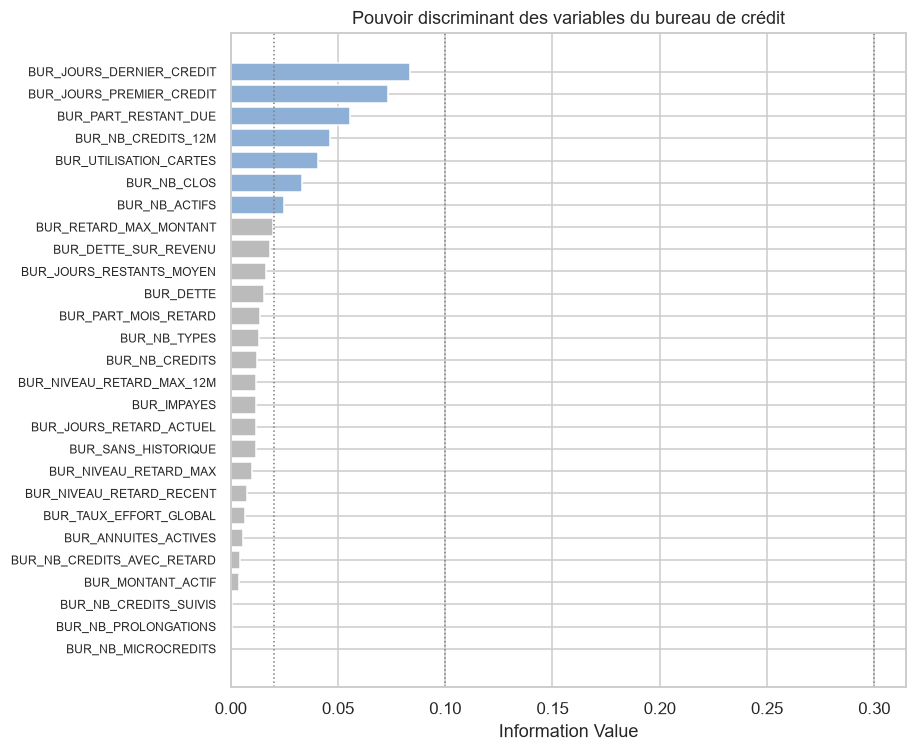

,IV
BUR_JOURS_DERNIER_CREDIT,0.084
BUR_JOURS_PREMIER_CREDIT,0.073
BUR_PART_RESTANT_DUE,0.055
BUR_NB_CREDITS_12M,0.046
BUR_UTILISATION_CARTES,0.041
BUR_NB_CLOS,0.033
BUR_NB_ACTIFS,0.025
BUR_RETARD_MAX_MONTANT,0.020
BUR_DETTE_SUR_REVENU,0.018
BUR_JOURS_RESTANTS_MOYEN,0.016


In [14]:
application = pd.read_parquet(DOSSIER_TRAITEES / "application_propre.parquet")
base = application.merge(variables_bureau, on="SK_ID_CURR", how="left", validate="one_to_one")
app = base[base["echantillon"] == "apprentissage"].reset_index(drop=True)
y = app["TARGET"]

nouvelles = [c for c in variables_bureau.columns if c != "SK_ID_CURR"]
encodeur = EncodeurWoE(nb_classes=10).fit(app[nouvelles], y)
iv_bureau = pd.Series(encodeur.iv_).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8.5, 7))
couleurs = ["#1F3B73" if v > 0.3 else "#4C72B0" if v > 0.1 else "#8EB0D6" if v > 0.02 else "#BBBBBB" for v in iv_bureau]
ax.barh(iv_bureau.index[::-1], iv_bureau.values[::-1], color=couleurs[::-1])
for seuil in (0.02, 0.1, 0.3):
    ax.axvline(seuil, color="grey", ls=":", lw=1)
ax.set(xlabel="Information Value", title="Pouvoir discriminant des variables du bureau de crédit")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()
iv_bureau.round(3).to_frame("IV").head(12)

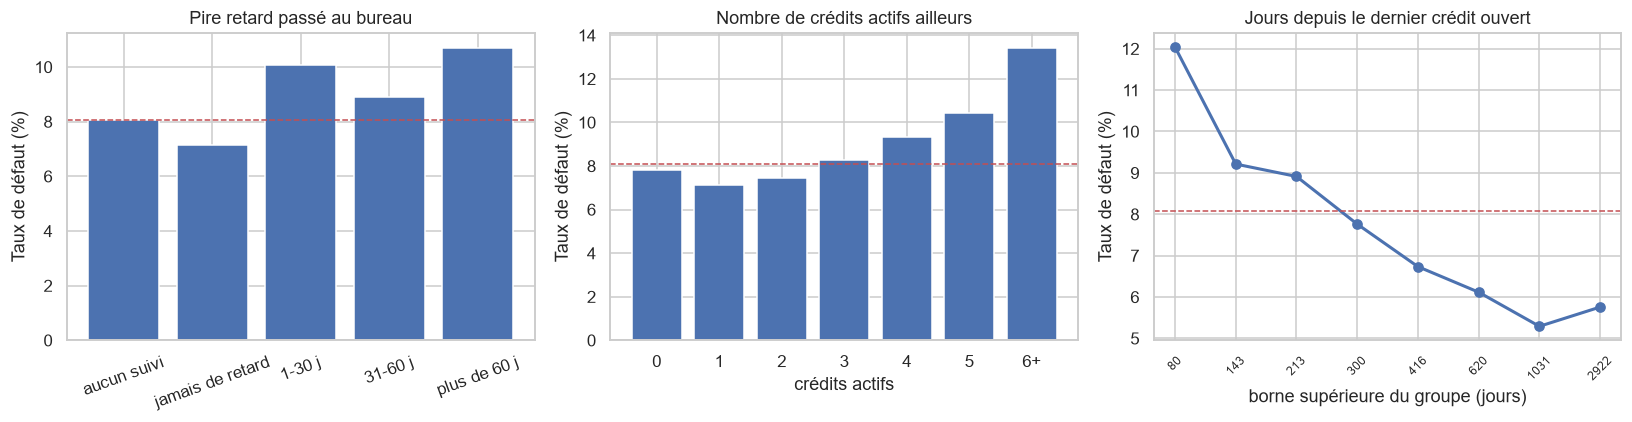

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
niveau = app["BUR_NIVEAU_RETARD_MAX"].fillna(-1).astype(int).clip(upper=3)
t = app.groupby(niveau)["TARGET"].agg(["mean", "size"])
etiquettes = {-1: "aucun suivi", 0: "jamais de retard", 1: "1-30 j", 2: "31-60 j", 3: "plus de 60 j"}
axes[0].bar([etiquettes[i] for i in t.index], t["mean"] * 100, color="#4C72B0")
axes[0].set(title="Pire retard passé au bureau", ylabel="Taux de défaut (%)")
axes[0].tick_params(axis="x", rotation=20)

actifs = app["BUR_NB_ACTIFS"].clip(upper=6)
t = app.groupby(actifs)["TARGET"].mean() * 100
axes[1].bar([str(int(i)) if i < 6 else "6+" for i in t.index], t.values, color="#4C72B0")
axes[1].set(title="Nombre de crédits actifs ailleurs", xlabel="crédits actifs", ylabel="Taux de défaut (%)")

anciennete = pd.qcut(app["BUR_JOURS_DERNIER_CREDIT"], 8)
t = app.groupby(anciennete, observed=True)["TARGET"].mean() * 100
axes[2].plot(range(len(t)), t.values, marker="o", color="#4C72B0", lw=2)
axes[2].set_xticks(range(len(t)))
axes[2].set_xticklabels([f"{int(i.right)}" for i in t.index], rotation=45, fontsize=8)
axes[2].set(title="Jours depuis le dernier crédit ouvert", xlabel="borne supérieure du groupe (jours)", ylabel="Taux de défaut (%)")
for ax in axes:
    ax.axhline(y.mean() * 100, color="#C44E52", ls="--", lw=1)
plt.tight_layout()
plt.show()

**Lecture.**
- **Aucune variable du bureau n'est forte seule.** Les plus discriminantes portent sur la **récence** : le délai depuis le dernier crédit ouvert (IV de 0,084) et depuis le premier (0,073). Viennent ensuite la part du crédit restant due (0,055), le nombre de crédits ouverts dans l'année (0,046) et l'utilisation des cartes (0,041).
- **Un client qui vient d'ouvrir un crédit ailleurs est plus risqué** : 12 % de défaut quand le dernier crédit date de moins de 80 jours, contre environ 5,5 % au-delà de 3 ans. Multiplier les demandes de crédit en peu de temps est un signal d'alerte classique pour les banques.
- **Le nombre de crédits actifs** joue de façon monotone au-delà de deux : de 7,4 % de défaut pour deux crédits en cours à 13,4 % pour six ou plus.
- **Les retards passés sont un signal net** (7,1 % de défaut sans aucun retard, 10,7 % après un retard de plus de 60 jours), mais leur IV reste faible car l'historique mensuel n'est connu que pour 29 % des clients.

# 6. Gain apporté au modèle

On reprend exactement la régression logistique de référence du notebook 02 et on lui ajoute les variables du bureau. Même pipeline, même validation croisée, mêmes plis : seule l'information change.

In [16]:
exclues = ["SK_ID_CURR", "TARGET", "echantillon"] + VARIABLES_EQUITE
qualitatives = [c for c in application.columns if c not in exclues and application[c].dtype.kind not in "biuf"]
numeriques_ref = [c for c in application.columns if c not in exclues and c not in qualitatives]

comparaison = [
    evaluer(pipeline_logistique(numeriques_ref, qualitatives), app[numeriques_ref + qualitatives], y,
            "Référence (table principale)"),
    evaluer(pipeline_logistique(numeriques_ref + nouvelles, qualitatives), app[numeriques_ref + nouvelles + qualitatives], y,
            "Référence + bureau de crédit"),
]
comparaison = pd.DataFrame(comparaison).set_index("modèle")
comparaison.loc["Gain"] = comparaison.iloc[1] - comparaison.iloc[0]
comparaison.round(4)

,AUC,écart-type AUC,Gini,AUC PR,Brier
modèle,,,,,
Référence (table principale),0.7471,0.0012,0.4941,0.2271,0.0686
Référence + bureau de crédit,0.7525,0.0016,0.5049,0.2350,0.0682
Gain,0.0054,0.0004,0.0108,0.0079,-0.0003


**Lecture.** L'ajout du bureau de crédit améliore la référence sur tous les critères. L'AUC passe de **0,7471 à 0,7525** (+0,5 point), le Gini gagne 1,1 point, l'AUC précision-rappel 0,8 point, et le score de Brier baisse. Le gain est régulier : les deux modèles sont évalués sur les mêmes plis, et l'écart dépasse largement la variabilité d'un pli à l'autre (écart-type d'environ 0,0015).

Le gain reste **modeste**, et c'est instructif. Les scores externes `EXT_SOURCE`, déjà présents dans la référence, sont très probablement calculés par des bureaux de crédit à partir de ces mêmes historiques : une grande partie de l'information était donc déjà dans le modèle.

## Prochaine étape

Les tables suivantes portent sur l'**historique propre à Home Credit** : demandes antérieures (acceptées ou refusées), échéanciers de remboursement, crédits à la consommation et cartes. Ces informations ne sont pas résumées par les scores externes, et on peut en attendre un gain plus important.